# Gayanara E-commerce: Exploratory Data Analysis
## 0. Persiapan Data
Menggunakan data bersih dari "01_data_cleaning". Revenue dihitungh dari order valid (delivered, shipped, processing), yaitu 2.521 order dengan total Rp.1,27 miliar.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
products = pd.read_csv("data_clean/products_clean.csv")
customers = pd.read_csv("data_clean/customers_clean.csv")
orders = pd.read_csv("data_clean/orders_clean.csv", parse_dates=["order_date"])
items = pd.read_csv("data_clean/order_items.csv")
reviews = pd.read_csv("data_clean/reviews.csv")
valid = orders[orders["is_valid_revenue"]].copy()
print(len(valid), valid["total_amount_idr"].sum())

2521 1265340379


## 1. Tren Revenue per Bulan
Revenue naik tajam di awal 2023, lalu trennya naik bertahap sampai puncak di Februari 2025 (Rp.66,3 juta).Titik terendah ada di pertengahan 2022 (sekitar Rp.10 juta).

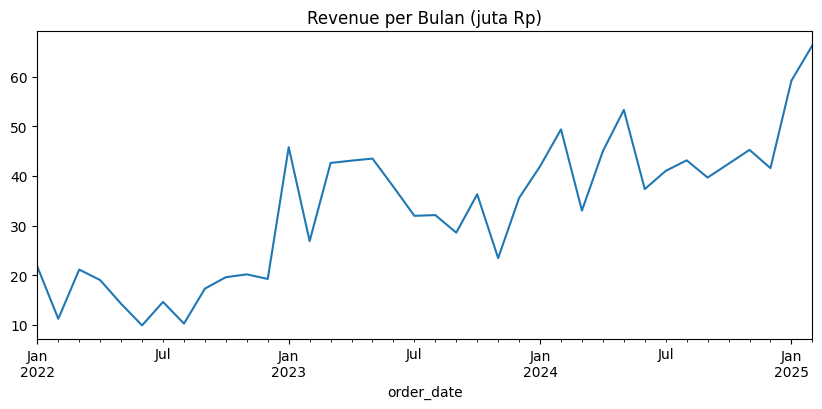

38
order_date
2025-02-01    66.302076
2025-01-01    59.189352
2024-05-01    53.314980
Name: total_amount_idr, dtype: float64


In [2]:
monthly = valid.set_index("order_date")["total_amount_idr"].resample("MS").sum() / 1e6
monthly.plot(figsize=(10, 4), title="Revenue per Bulan (juta Rp)")
plt.show()
print(len(monthly))
print(monthly.sort_values(ascending=False).head(3))

## 2. Revenue per Kategori
Lima kategori berselisih tipis (Rp.216 sampai 224 juta). T-Shirt paling rendah (Rp.195,6 juta). Angka dihitung dari subtotal item sebelum diskon.

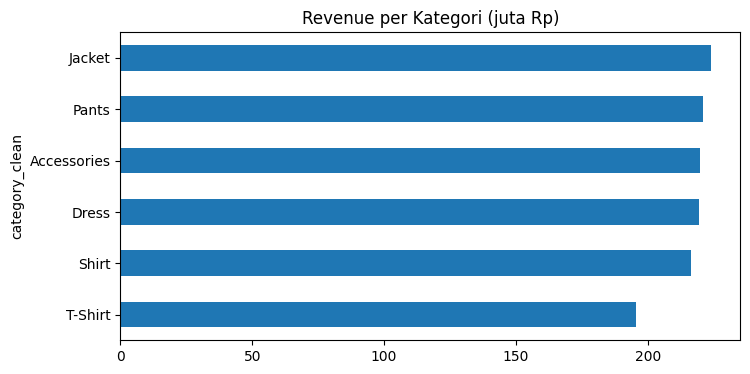

category_clean
Jacket         224.0
Pants          221.0
Accessories    220.0
Dress          219.5
Shirt          216.6
T-Shirt        195.6
Name: subtotal_idr, dtype: float64


In [3]:
cat = (items.merge(valid[["order_id"]], on="order_id")
       .merge(products[["product_id", "category_clean"]], on="product_id")
       .groupby("category_clean")["subtotal_idr"].sum().sort_values(ascending=False) / 1e6)
cat.plot(kind="barh", figsize=(8, 4), title="Revenue per Kategori (juta Rp)")
plt.gca().invert_yaxis()
plt.show()
print(cat.round(1))

## 3. Revenue per Kota
Ada 20 kota tujuan dan persebarannya merata. Semarang tertinggi (Rp.76,6 juta), tapi ordernya leih sedikit dari Depok dan Medan, artinya nilai per ordernya lebih besar.

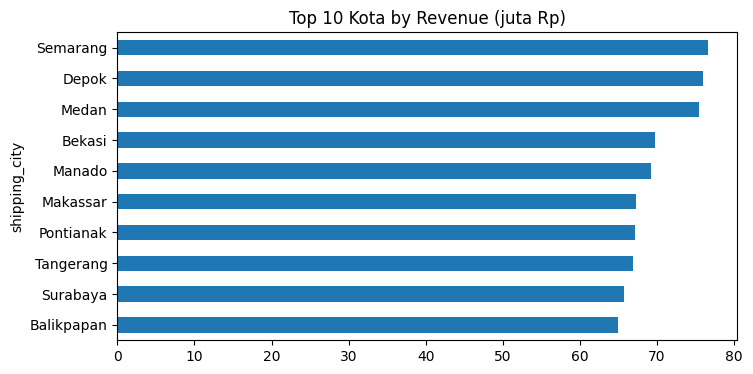

20
               jumlah_order  revenue_juta
shipping_city                            
Semarang                141          76.6
Depok                   150          76.0
Medan                   155          75.5
Bekasi                  151          69.7
Manado                  138          69.2


In [4]:
city = (valid.groupby("shipping_city")
        .agg(jumlah_order=("order_id", "count"), revenue_juta=("total_amount_idr", lambda s: s.sum() / 1e6))
        .sort_values("revenue_juta", ascending=False))
city["revenue_juta"].head(10).plot(kind="barh", figsize=(8, 4), title="Top 10 Kota by Revenue (juta Rp)")
plt.gca().invert_yaxis()
plt.show()
print(len(city))
print(city.head(5).round(1))

## 4. Dampak Promo
41% order pakai promo, tapi rata-rata nilainya (Rp.484.538) sekitar 6% lebih kecil dari order tanpa promo (Rp.513.830). Total diskon hanya Rp.31,4 juta (sekitar 2,4% dari revenue kotor).

In [5]:
valid["pakai_promo"] = valid["promo_code"].notna()
promo = valid.groupby("pakai_promo")["total_amount_idr"].agg(["count", "mean"]).round(0)
print(promo)
print("total diskon (juta):", round(valid["discount_amount_idr"].sum() / 1e6, 1))

             count      mean
pakai_promo                 
False         1496  513830.0
True          1025  484538.0
total diskon (juta): 31.4


## 5. Order Gagal (Cancelled dan Returned)
16% order gagal. J&T (18,4%) dan OVO (18,7%) tertinggi, tapi selisih dengan yamng lain hanya 3 sampai 4 poin, jadi bisa jadi variasi acak dan perlu dipantau.

In [6]:
orders["gagal"] = orders["order_status"].isin(["cancelled", "returned"])
print("rate gagal:", round(orders["gagal"].mean() * 100, 1), "%")
for kolom in ["courier", "payment_method"]:
    print((orders.groupby(kolom)["gagal"].mean() * 100).round(1).sort_values(ascending=False))

rate gagal: 16.0 %
courier
J&T              18.4
Anteraja         16.9
JNE              15.0
Pos Indonesia    14.3
SiCepat          14.2
Name: gagal, dtype: float64
payment_method
OVO              18.7
Kartu Kredit     16.6
Transfer Bank    15.7
QRIS             15.0
GoPay            14.2
Name: gagal, dtype: float64
